## Which categories are relevant to pitching style?
- Ball speed
    - `release_speed`
- Pitcher Extension
    - `release_extension`
- Release position
    - `release_pos_x`
    - `release_pos_y`
    - `release_pos_z`
- Ball Movement
    - `pfx_x`
    - `pfx_z`
- Ball Spin
    - `release_spin`
    - `spin_axis`
- Arrival Position
    - `plate_x`
    - `plate_z`
    - `zone`
- Pitcher Handedness
    - `p_throws`
- Pitch types
    - `pitch_type`
    - `pitch_name`
- Pitch Info
    - `description`
    - `events`
- Effectiveness
    - Outs / PA
    - Whiff%
    - How many innings pitched on average
- Aggregate Stats
    - How often they pitch a given type based on pitch count / base runner count / batter stance
        - `balls`
        - `strikes`
        - `stand`
        - `on_1b`
        - `on_2b`
        - `on_3b`


## Idea: Try to aggregate stats for each pitcher over all plate appearances
i.e. create aggregate stats for each pitcher based on the above stats that averages out their pitches over the duration of the postseason.

Could group into several major types
i.e. 
- Engineered stats for pitch type (pitch types by frequency thrown, number of types of pitches he can throw, how often he uses a fastball, how often he uses a breaking ball, how often he uses an offspeed pitch, etc.)
- Engineered stats for pitch velocity (mean speed for each pitch type, max speed for each pitch type/ 95th percentile speed, velocity variance for each pitch type)
- Engineered pitch movement stats (horizontal movement avg by type, vertical movement avg, avg spin rate and spin axis by type, std of movement in each direction by type)
- Engineered release mechanics stats (avg release position by type, avg release extension, std of each by type)
- Engineered command stats (Whiff%, Percentage of pitches in the strike zone, percentage of each pitch type in each mini-zone as avg, and std, pitch rate changes by situation)
- Misc Stats (Outs / PA, Innings Pitched Avg/Std, Handedness, Strikeout rate, walk rate, ERA, WHIP, ground ball rate, hard contact rate, avg contact quality (woba))

Use these features and weigh them based on blocks (i.e. there are more pitch type subtypes stats than speed ones, so weight them differently), then use PCA to reduce dimensions (try wihtou PCA too), then use clustering models to compare and use elbow curve to find cluster types and place jays within them (k-means, GMM, HDBScan)


# Imports

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

In [33]:
pd.set_option("display.max_columns", 60)

# Constants

In [34]:
DATA_PATH = "MLB_Data.csv"
JAYS = "TOR"
MIN_PITCHES = 50
MIN_PITCHES_PER_GROUP = 8
MAX_Z = 4.0
MAX_NAN_FRAC = 0.6
PCA_VARIANCE = 0.70

FASTBALLS = {"FF", "FA", "SI", "FT", "FC"}
BREAKING = {"SL", "ST", "SV", "CU", "KC", "CS"}
OFFSPEED = {"CH", "FS", "FO", "SC", "KN", "EP"}
NON_PITCHES = {"PO", "IN", "AB", "UN"}

SWING = {"swinging_strike", "swinging_strike_blocked", "foul_tip", "foul", "foul_bunt", "missed_bunt",
         "bunt_foul_tip", "hit_into_play"}
WHIFF = {"swinging_strike", "swinging_strike_blocked", "foul_tip", "missed_bunt"}
PA_EVENTS = {"single", "double", "triple", "home_run", "field_out", "strikeout", "strikeout_double_play",
             "walk", "intent_walk", "hit_by_pitch", "force_out", "grounded_into_double_play", "double_play",
             "fielders_choice", "fielders_choice_out", "field_error", "sac_fly", "sac_bunt",
             "sac_fly_double_play", "sac_bunt_double_play", "triple_play", "catcher_interf", "truncated_pa"}
OUTS_ON_EVENT = {"strikeout": 1, "field_out": 1, "force_out": 1, "fielders_choice_out": 1, "sac_fly": 1,
                 "sac_bunt": 1, "other_out": 1, "caught_stealing_2b": 1, "caught_stealing_3b": 1,
                 "caught_stealing_home": 1, "pickoff_1b": 1, "pickoff_2b": 1, "pickoff_3b": 1,
                 "pickoff_caught_stealing_2b": 1, "pickoff_caught_stealing_3b": 1,
                 "pickoff_caught_stealing_home": 1,
                 "grounded_into_double_play": 2, "double_play": 2, "strikeout_double_play": 2,
                 "sac_fly_double_play": 2, "sac_bunt_double_play": 2, "triple_play": 3}
HITS = {"single", "double", "triple", "home_run"}
GROUPS = ["FB", "BR", "OS"]

BLOCK_WEIGHTS = {
    "pitch_mix":   1.0,
    "velocity":    1.0,
    "movement":    1.0,
    "release":     1.0,
    "command":     1.0,
    "situational": 0.75,
    "results":     0.5,
}

K_RANGE = range(2, 11)
SHRINK_M = 15

CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948",
                  "#7a7a7a", "#8c564b"]
CLUSTER_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "h", "<", ">"]

# Bookkeeping Code

In [35]:
FIG_DIR = Path("figures")
if FIG_DIR is not None:
    FIG_DIR.mkdir(exist_ok=True)

def savefig(fig, name):
    if FIG_DIR is not None:
        fig.savefig(f'{FIG_DIR}/{name}.png', dpi=130, bbox_inches="tight")

# Loading Data

In [36]:
def load_mlb(path=DATA_PATH):
    df = pd.read_csv(path, low_memory=False)
    print(f"Original DF Size: {len(df.index)}")

    df = df[df["pitch_type"].notna() & ~df["pitch_type"].isin(NON_PITCHES)]
    print(f"DF Size (V2): {len(df.index)}")

    df = df[df["release_speed"].notna()]
    print(f"DF Size (V3): {len(df.index)}")

    df["game_date"] = pd.to_datetime(df["game_date"])

    return df.sort_values(["game_pk", "at_bat_number", "pitch_number"]).reset_index(drop=True)

In [37]:
postseason_data = load_mlb()

Original DF Size: 14096
DF Size (V2): 14096
DF Size (V3): 14096


# EDA

In [38]:
print(f"Pitches: {len(postseason_data.index)}")
print(f"Pitchers: {len(postseason_data["pitcher"].unique())}")
print(f"Games: {len(postseason_data["game_pk"].unique())}")

Pitches: 14096
Pitchers: 143
Games: 47


# Feature Engineering

In [39]:
def feature_engineering(df):
    d = df.copy()
    d["pitch_group"] = np.select([d["pitch_type"].isin(FASTBALLS), d["pitch_type"].isin(BREAKING),
                    d["pitch_type"].isin(OFFSPEED)], ["FB", "BR", "OS"], "OTHER")
    d = d[d["pitch_group"] != "OTHER"]

    sign = np.where(d["p_throws"] == "L", -1.0, 1.0)
    d["hb_in"] = -d["pfx_x"] * 12 * sign
    d["ivb_in"] = d["pfx_z"] * 12
    d["rel_x_arm"] = -d["release_pos_x"] * sign
    d["plate_x_arm"] = -d["plate_x"] * sign
    axis = np.where(d["p_throws"] == "L", 360 - d["spin_axis"], d["spin_axis"])
    d["spin_axis_cos"] = np.cos(np.radians(axis))
    d["spin_axis_sin"] = np.sin(np.radians(axis))
    d["spin_per_speed"] = d["release_spin_rate"] / d["release_speed"]
    d["arm_angle_proxy"] = np.degrees(np.arctan2(d["release_pos_z"], d["rel_x_arm"].abs()))

    d["is_swing"] = d["description"].isin(SWING)
    d["is_whiff"] = d["description"].isin(WHIFF)
    d["is_called_strike"] = d["description"].eq("called_strike")
    d["in_zone"] = d["zone"].between(1, 9)
    d["is_chase"] = d["is_swing"] & ~d["in_zone"]
    d["is_csw"] = d["is_whiff"] | d["is_called_strike"]
    d["is_fb"] = d["pitch_group"].eq("FB")
    d["is_br"] = d["pitch_group"].eq("BR")
    d["is_os"] = d["pitch_group"].eq("OS")
    d["is_non_fb"] = ~d["is_fb"]

    d["count_state"] = np.select([d["strikes"] > d["balls"], d["balls"] > d["strikes"]], ["ahead", "behind"], "even")
    d["two_strikes"] = d["strikes"].eq(2)
    d["first_pitch"] = d["balls"].eq(0) & d["strikes"].eq(0)
    d["runners_on"] = d[["on_1b", "on_2b", "on_3b"]].notna().any(axis=1)
    d["risp"] = d[["on_2b", "on_3b"]].notna().any(axis=1)
    d["same_hand"] = d["stand"].eq(d["p_throws"])

    d["pitcher_team"] = np.where(d["inning_topbot"].eq("Top"), d["home_team"], d["away_team"])

    d["is_pa"] = d["events"].isin(PA_EVENTS)
    d["outs_on_play"] = d["events"].map(OUTS_ON_EVENT).fillna(0)
    d["runs_on_play"] = (d["post_bat_score"] - d["bat_score"]).clip(lower=0).fillna(0)
    d["is_bip"] = d["type"].eq("X")

    return d

In [40]:
pitches = feature_engineering(postseason_data)
pitches[["pitcher", "pitch_type", "pitch_group", "release_speed", "hb_in", "ivb_in", "is_swing", "is_whiff"]].head()

,pitcher,pitch_type,pitch_group,release_speed,hb_in,ivb_in,is_swing,is_whiff
0,605483,FF,FB,96.6,3.24,18.72,True,False
1,605483,FF,FB,96.8,5.28,19.20,False,False
2,605483,FF,FB,96.0,4.80,20.28,True,False
3,605483,CU,BR,81.5,-13.20,-10.44,True,True
4,605483,CU,BR,83.1,-16.32,-5.40,True,False


In [41]:
def group_pitcher_data(df):
    appearances = df.groupby(["pitcher", "game_pk"]).agg(
        n_pitches=("release_speed", "size"),
        outs=("outs_on_play", "sum"),
        runs=("runs_on_play", "sum"),
        batters_faced=("is_pa", "sum"),
        first_inning=("inning", "min"),
        last_inning=("inning", "max"),
        fb_velo=("release_speed", lambda x: x[df.loc[x.index, "is_fb"]].mean())
    ).reset_index()

    appearances["ip"] = appearances["outs"] / 3
    appearances["is_start"] = appearances["first_inning"].eq(1)

    return appearances

In [42]:
appearances = group_pitcher_data(pitches)
appearances.head()

,pitcher,game_pk,n_pitches,outs,runs,batters_faced,first_inning,last_inning,fb_velo,ip,is_start
0,453286,813024,54,13.0,1,18,1,5,94.313043,4.333333,True
1,453286,813032,79,12.0,2,18,1,5,93.945455,4.000000,True
2,453286,813035,87,16.0,1,22,1,6,94.091304,5.333333,True
3,458677,813070,23,5.0,0,5,3,4,94.215385,1.666667,False
4,477132,813032,8,1.0,0,1,12,12,91.900000,0.333333,False


In [43]:
def get_per_group_stats(df, spec, min_n=MIN_PITCHES_PER_GROUP):
    agg = df.groupby(["pitcher", "pitch_group"]).agg(**spec, _n=("release_speed", "size"))
    agg.loc[agg["_n"] < min_n, :] = np.nan
    wide = agg.drop(columns="_n").unstack("pitch_group")
    wide.columns = [f"{g}_{stat}" for stat, g in wide.columns]
    return wide[[c for g in GROUPS for c in wide.columns if c.startswith(g + "_")]]

def entropy(p):
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def p95(s): return s.quantile(0.95)
def p05(s): return s.quantile(0.05)

def safe_rate(num, den, min_den=1):
    return np.where(den >= min_den, num / den.replace(0, np.nan), np.nan)

def shrunk_rate(d, mask, flag, prior, m=SHRINK_M):
    s = d[mask].groupby("pitcher")[flag].agg(["sum", "count"]).reindex(prior.index).fillna(0)
    return (s["sum"] + m * prior) / (s["count"] + m)

In [44]:
def pitch_mix(df):
    usage = pd.crosstab(df["pitcher"], df["pitch_type"], normalize="index").add_prefix("usage_")
    grp = pd.crosstab(df["pitcher"], df["pitch_group"], normalize="index").reindex(columns=GROUPS, fill_value=0)
    grp.columns = [f"usage_grp_{g}" for g in grp.columns]
    out = usage.join(grp)
    raw_usage = usage.values
    out["n_pitch_types_5pct"] = (raw_usage >= 0.05).sum(axis=1)
    out["pitch_mix_entropy"] = [entropy(r) for r in raw_usage]
    out["primary_pitch_share"] = raw_usage.max(axis=1)
    return out

def velo_stats(df):
    out = get_per_group_stats(df, {"velo_mean": ("release_speed", "mean"), "velo_p95": ("release_speed", p95),
        "velo_max": ("release_speed", "max"), "velo_std": ("release_speed", "std"),
        "eff_velo_mean": ("effective_speed", "mean")})
    out["velo_gap_FB_OS"] = out["FB_velo_mean"] - out["OS_velo_mean"]
    out["velo_gap_FB_BR"] = out["FB_velo_mean"] - out["BR_velo_mean"]
    out["velo_mean_all"] = df.groupby("pitcher")["release_speed"].mean()
    return out

def movement_stats(df):
    out = get_per_group_stats(df, {"hb_mean": ("hb_in", "mean"), "hb_std": ("hb_in", "std"),
        "ivb_mean": ("ivb_in", "mean"), "ivb_std": ("ivb_in", "std"),
        "spin_mean": ("release_spin_rate", "mean"), "spin_std": ("release_spin_rate", "std"),
        "axis_cos": ("spin_axis_cos", "mean"), "axis_sin": ("spin_axis_sin", "mean"),
        "spin_per_speed": ("spin_per_speed", "mean")})

    return out

def release_stats(df):
    grp = df.groupby("pitcher")
    out = pd.DataFrame({
        "rel_x_mean": grp["rel_x_arm"].mean(), "rel_x_std": grp["rel_x_arm"].std(),
        "rel_z_mean": grp["release_pos_z"].mean(), "rel_z_std": grp["release_pos_z"].std(),
        "rel_y_mean": grp["release_pos_y"].mean(),
        "ext_mean": grp["release_extension"].mean(), "ext_std": grp["release_extension"].std(),
        "arm_angle_proxy": grp["arm_angle_proxy"].mean(),
    })

    by_grp = get_per_group_stats(df, {"rel_x": ("rel_x_arm", "mean"), "rel_z": ("release_pos_z", "mean"),
        "ext": ("release_extension", "mean")})

    out = out.join(by_grp)
    return out

def command_stats(df):
    grp = df.groupby("pitcher")
    swings = grp["is_swing"].sum()
    ooz = grp["in_zone"].apply(lambda s: (~s).sum())

    out = pd.DataFrame({
        "zone_pct": grp["in_zone"].mean(),
        "whiff_pct": safe_rate(grp["is_whiff"].sum(), swings),
        "chase_pct": safe_rate(grp["is_chase"].sum(), ooz),
        "csw_pct": grp["is_csw"].mean(),
        "plate_z_mean": grp["plate_z"].mean(),
        "plate_z_std": grp["plate_z"].std(),
        "plate_x_arm_mean": grp["plate_x_arm"].mean(),
        "plate_x_arm_std": grp["plate_x_arm"].std(),
    })

    grp_2 = df.groupby(["pitcher", "pitch_group"]).agg(
        sw=("is_swing", "sum"),
        wh=("is_whiff", "sum"),
        z=("in_zone", "mean"),
        px=("plate_x_arm", "mean"),
        pz=("plate_z", "mean"),
        n=("is_swing", "size")
    )
    grp_2["whiff"] = safe_rate(grp_2["wh"], grp_2["sw"], min_den=5)
    grp_2.loc[grp_2["n"] < MIN_PITCHES_PER_GROUP, ["z", "px", "pz"]] = np.nan
    wide = grp_2[["whiff", "z", "px", "pz"]].unstack("pitch_group")
    wide.columns = [f"{gname}_{ {'whiff': 'whiff_pct', 'z': 'zone_pct', 'px': 'plate_x_arm', 'pz': 'plate_z'}[s] }"
                        for s, gname in wide.columns]
    out = out.join(wide[[c for c in wide.columns if c.split("_")[0] in GROUPS]])
    zones = pd.crosstab(df["pitcher"], df["zone"].astype("Int64"), normalize="index")
    zones = zones.reindex(columns=[*range(1, 10), 11, 12, 13, 14], fill_value=0)
    zones.columns = [f"zone_{z}_pct" for z in zones.columns]
    return out.join(zones)

def situational_stats(df):
    fb_all = df.groupby("pitcher")["is_fb"].mean()
    br_all = df.groupby("pitcher")["is_br"].mean()
    os_all = df.groupby("pitcher")["is_os"].mean()
    nfb_all = 1 - fb_all

    out = pd.DataFrame(index=fb_all.index)
    for state in ["ahead", "even", "behind"]:
        out[f"fb_pct_{state}"] = shrunk_rate(df, df["count_state"].eq(state), "is_fb", fb_all)

    out["fb_pct_risp"] = shrunk_rate(df, df["risp"], "is_fb", fb_all)
    out["fb_pct_bases_empty"] = shrunk_rate(df, ~df["runners_on"], "is_fb", fb_all)
    out["br_pct_same_hand"] = shrunk_rate(df, df["same_hand"], "is_br", br_all)
    out["br_pct_opp_hand"] = shrunk_rate(df, ~df["same_hand"], "is_br", br_all)
    out["os_pct_same_hand"] = shrunk_rate(df, df["same_hand"], "is_os", os_all)
    out["os_pct_opp_hand"] = shrunk_rate(df, ~df["same_hand"], "is_os", os_all)

    out["fb_pct_runners_on"] = shrunk_rate(df, df["runners_on"], "is_fb", fb_all)
    out["fb_pct_bases_empty"] = shrunk_rate(df, ~df["runners_on"], "is_fb", fb_all)
    out["fb_pct_risp"] = shrunk_rate(df, df["risp"], "is_fb", fb_all)
    out["fb_shift_behind_vs_ahead"] = out["fb_pct_behind"] - out["fb_pct_ahead"]
    out["fb_shift_runners_vs_empty"] = out["fb_pct_runners_on"] - out["fb_pct_bases_empty"]
    return out

def results_stats(df, app):
    pa = df[df["is_pa"]]
    g = pa.groupby("pitcher")
    n_pa = g.size()
    k = g["events"].apply(lambda s: s.isin({"strikeout", "strikeout_double_play"}).sum())
    bb = g["events"].apply(lambda s: s.isin({"walk", "intent_walk"}).sum())
    h = g["events"].apply(lambda s: s.isin(HITS).sum())
    pa_outs = g["outs_on_play"].sum()

    a = app.groupby("pitcher")
    ip_total = a["ip"].sum()
    runs_total = a["runs"].sum()

    out = pd.DataFrame({
        "k_pct": k / n_pa, 
        "bb_pct": bb / n_pa,
        "outs_per_pa": pa_outs / n_pa,
        "ip_per_app_mean": a["ip"].mean(),
        "ip_per_app_std": a["ip"].std().fillna(0),
        "pitches_per_app_mean": a["n_pitches"].mean(),
        "bf_per_app_mean": a["batters_faced"].mean(),
        "n_appearances": a.size(),
        "start_pct": a["is_start"].mean(),
        "ra9": 9 * runs_total / ip_total.replace(0, np.nan),
        "whip": (h.reindex(ip_total.index).fillna(0) + bb.reindex(ip_total.index).fillna(0)) / ip_total.replace(0, np.nan),
    })

    bip = df[df["is_bip"]]
    gb = bip.groupby("pitcher")

    out["gb_pct"] = gb["bb_type"].apply(lambda s: s.eq("ground_ball").mean())
    out["hard_hit_pct"] = gb["launch_speed"].apply(lambda s: (s >= 95).mean())
    out["avg_exit_velo"] = gb["launch_speed"].mean()
    out["avg_launch_angle"] = gb["launch_angle"].mean()

    den = pa["woba_denom"].fillna(0)
    xval = np.where(pa["is_bip"] & pa["estimated_woba_using_speedangle"].notna(),
                        pa["estimated_woba_using_speedangle"], pa["woba_value"].fillna(0))
    tmp = pd.DataFrame({"pitcher": pa["pitcher"], "w": pa["woba_value"].fillna(0) * (den > 0), "x": xval * (den > 0), "den": den})
    s = tmp.groupby("pitcher").sum()
    out["woba_allowed"] = s["w"] / s["den"].replace(0, np.nan)
    out["xwoba_allowed"] = s["x"] / s["den"].replace(0, np.nan)
    return out

def build_all_features(df, app, min_pitches=MIN_PITCHES):
    meta = df.groupby("pitcher").agg(
            player_name=("player_name", lambda s: s.mode().iat[0]),
            team=("pitcher_team", lambda s: s.mode().iat[0]),
            p_throws=("p_throws", lambda s: s.mode().iat[0]),
            n_pitches=("release_speed", "size"))
    keep = meta.index[meta["n_pitches"] >= min_pitches]
    df = df[df["pitcher"].isin(keep)]
    app = app[app["pitcher"].isin(keep)]

    blocks = {
        "pitch_mix": pitch_mix(df), 
        "velocity": velo_stats(df), 
        "movement": movement_stats(df),
        "release": release_stats(df),
        "command": command_stats(df),
        "situational": situational_stats(df),
        "results": results_stats(df, app),
    }

    feats = pd.concat([b.reindex(keep) for b in blocks.values()], axis=1)
    block_of = {c: name for name, b in blocks.items() for c in b.columns}
    feats = feats.replace([np.inf, -np.inf], np.nan)
    return meta.loc[keep], feats, block_of

In [45]:
meta, features, block_of = build_all_features(pitches, appearances)

In [46]:
print(f"{len(features)} pitchers x {features.shape[1]} features")
print(pd.Series(block_of).value_counts().rename("n_features"))
features.head()

89 pitchers x 140 features
command        33
movement       27
velocity       18
release        17
results        17
pitch_mix      16
situational    12
Name: n_features, dtype: int64


,usage_CH,usage_CU,usage_FC,usage_FF,usage_FS,usage_KC,usage_SI,usage_SL,usage_ST,usage_SV,usage_grp_FB,usage_grp_BR,usage_grp_OS,n_pitch_types_5pct,pitch_mix_entropy,primary_pitch_share,FB_velo_mean,FB_velo_p95,FB_velo_max,FB_velo_std,FB_eff_velo_mean,BR_velo_mean,BR_velo_p95,BR_velo_max,BR_velo_std,BR_eff_velo_mean,OS_velo_mean,OS_velo_p95,OS_velo_max,OS_velo_std,...,zone_14_pct,fb_pct_ahead,fb_pct_even,fb_pct_behind,fb_pct_risp,fb_pct_bases_empty,br_pct_same_hand,br_pct_opp_hand,os_pct_same_hand,os_pct_opp_hand,fb_pct_runners_on,fb_shift_behind_vs_ahead,fb_shift_runners_vs_empty,k_pct,bb_pct,outs_per_pa,ip_per_app_mean,ip_per_app_std,pitches_per_app_mean,bf_per_app_mean,n_appearances,start_pct,ra9,whip,gb_pct,hard_hit_pct,avg_exit_velo,avg_launch_angle,woba_allowed,xwoba_allowed
pitcher,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
453286,0.122727,0.145455,0.054545,0.459091,0.000000,0.000000,0.000000,0.218182,0.0,0.000000,0.513636,0.363636,0.122727,5,1.999728,0.459091,94.079646,95.900,96.5,1.722289,93.474336,82.961250,88.600,89.4,4.787682,82.747500,85.866667,87.470,87.5,1.248692,...,0.290909,0.388707,0.593313,0.573509,0.494724,0.517117,0.470455,0.265035,0.048674,0.191084,0.507658,0.184802,-0.009459,0.189655,0.103448,0.706897,4.555556,0.693889,73.333333,19.333333,3,1.000000,2.634146,1.317073,0.219512,0.487805,93.746341,25.585366,0.327586,0.369310
477132,0.000000,0.125000,0.000000,0.339286,0.017857,0.000000,0.000000,0.517857,0.0,0.000000,0.339286,0.642857,0.017857,3,1.499434,0.517857,89.815789,91.630,91.9,1.399708,90.484211,84.763889,89.425,89.7,5.885826,85.355556,NaN,NaN,NaN,NaN,...,0.250000,0.299370,0.419147,0.293527,0.252029,0.416872,0.640056,0.646939,0.005252,0.036224,0.299812,-0.005843,-0.117060,0.000000,0.142857,0.357143,0.833333,0.707107,28.000000,7.000000,2,0.000000,27.000000,4.800000,0.416667,0.416667,83.641667,5.166667,0.788462,0.639846
500779,0.163265,0.142857,0.000000,0.132653,0.000000,0.000000,0.418367,0.000000,0.0,0.142857,0.551020,0.285714,0.163265,5,2.141533,0.418367,91.642593,92.975,93.8,0.818559,91.729630,80.171429,81.265,81.4,0.723601,80.421429,87.056250,88.475,88.7,1.004635,...,0.224490,0.515006,0.550278,0.601765,0.580113,0.537881,0.375661,0.220077,0.063870,0.235797,0.568460,0.086759,0.030579,0.120000,0.080000,0.600000,2.500000,0.707107,49.000000,12.500000,2,0.500000,5.400000,2.000000,0.450000,0.400000,92.295000,12.300000,0.402000,0.397280
518585,0.000000,0.000000,0.000000,0.555556,0.317460,0.000000,0.015873,0.111111,0.0,0.000000,0.571429,0.111111,0.317460,3,1.443709,0.555556,94.530556,95.425,95.9,0.590312,95.125000,NaN,NaN,NaN,NaN,NaN,80.820000,82.515,82.8,1.511569,...,0.269841,0.502857,0.465986,0.721254,0.555901,0.598901,0.136905,0.072072,0.335034,0.290862,0.560768,0.218397,-0.038134,0.250000,0.125000,0.687500,0.916667,0.319142,15.750000,4.000000,4,0.000000,7.363636,1.363636,0.400000,0.600000,84.000000,13.300000,0.278125,0.323562
519141,0.000000,0.000000,0.000000,0.802326,0.000000,0.197674,0.000000,0.000000,0.0,0.000000,0.802326,0.197674,0.000000,2,0.717252,0.802326,93.588406,94.800,95.4,0.802301,92.537681,85.582353,87.220,87.3,1.203762,84.276471,NaN,NaN,NaN,NaN,...,0.011628,0.673748,0.875727,0.904351,0.801744,0.784487,0.166138,0.239302,0.000000,0.000000,0.858389,0.230603,0.073901,0.315789,0.000000,0.947368,1.000000,0.000000,14.333333,3.166667,6,0.166667,1.500000,0.166667,0.076923,0.538462,90.861538,27.615385,0.105263,0.283526


# PCA

In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

In [48]:
def build_matrix(feats, block_of, weights=BLOCK_WEIGHTS, max_nan=MAX_NAN_FRAC, clip=MAX_Z):
    X = feats.loc[:, feats.isna().mean() <= max_nan]
    X = X.loc[:, X.std(skipna=True) > 1e-9]
    X = X.fillna(X.median())
    Z = StandardScaler().fit_transform(X).clip(-clip, clip)
    blocks = pd.Series({c: block_of[c] for c in X.columns})
    n_in_block = blocks.map(blocks.value_counts())
    col_w = blocks.map(weights).values / np.sqrt(n_in_block.values)
    Zw = pd.DataFrame(Z * col_w, index=X.index, columns=X.columns)
    return Zw, X, blocks

In [49]:
Xw, X_imputed, col_blocks = build_matrix(features, block_of)

In [50]:
pca_full = PCA(random_state=1).fit(Xw)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VARIANCE) + 1)
X_pca = PCA(n_components=n_pc, random_state=1).fit_transform(Xw)
print(f"{n_pc} PCs explain {cum[n_pc-1]:.1%} of variance")

14 PCs explain 70.5% of variance


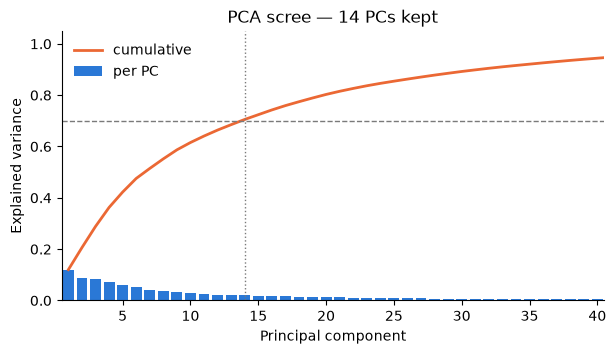

In [51]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, color="#2a78d6", width=0.8, label="per PC")
ax.plot(range(1, len(cum) + 1), cum, color="#eb6834", lw=2, label="cumulative")
ax.axhline(PCA_VARIANCE, color="#7a7a7a", lw=1, ls="--")
ax.axvline(n_pc, color="#7a7a7a", lw=1, ls=":")
ax.set(xlabel="Principal component", ylabel="Explained variance", title=f"PCA scree — {n_pc} PCs kept")
ax.set_xlim(0.5, min(len(cum), 40) + 0.5)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
savefig(fig, "pca_scree"); plt.show()

# Clustering

In [52]:
def knee_point(ks, values):
    ks, v = np.asarray(list(ks), float), np.asarray(values, float)
    xn = (ks - ks.min()) / (ks.max() - ks.min())
    yn = (v - v.min()) / (v.max() - v.min() + 1e-12)
    dist = np.abs(yn - (yn[0] + (yn[-1] - yn[0]) * xn))
    return int(ks[np.argmax(dist)])

def evaluate_k(X, k_range=K_RANGE, gmm_cov="full"):
    X = np.asarray(X)
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=25, random_state=1).fit(X)
        gm = GaussianMixture(n_components=k, covariance_type=gmm_cov, n_init=5, reg_covar=1e-3,
                             random_state=1).fit(X)
        gl = gm.predict(X)
        rows.append(dict(k=k, inertia=km.inertia_, km_silhouette=silhouette_score(X, km.labels_),
                         gmm_bic=gm.bic(X), gmm_aic=gm.aic(X),
                         gmm_silhouette=silhouette_score(X, gl) if len(set(gl)) > 1 else np.nan))
    res = pd.DataFrame(rows).set_index("k")
    choice = {"kmeans_elbow": knee_point(res.index, res["inertia"]),
              "kmeans_best_silhouette": int(res["km_silhouette"].idxmax()),
              "gmm_min_bic": int(res["gmm_bic"].idxmin()),
              "gmm_bic_elbow": knee_point(res.index, res["gmm_bic"])}
    return res, choice

pca {'kmeans_elbow': 5, 'kmeans_best_silhouette': 3, 'gmm_min_bic': 2, 'gmm_bic_elbow': 6}


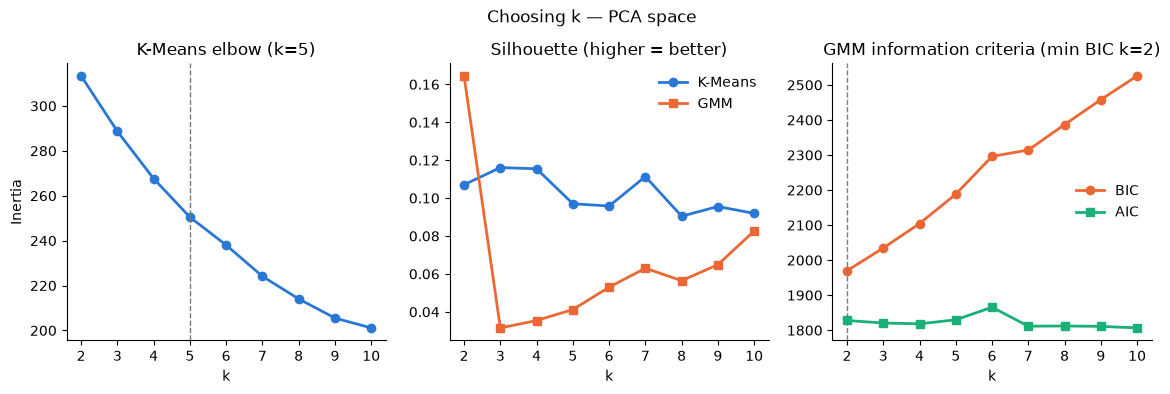

no_pca {'kmeans_elbow': 6, 'kmeans_best_silhouette': 2, 'gmm_min_bic': 2, 'gmm_bic_elbow': 3}


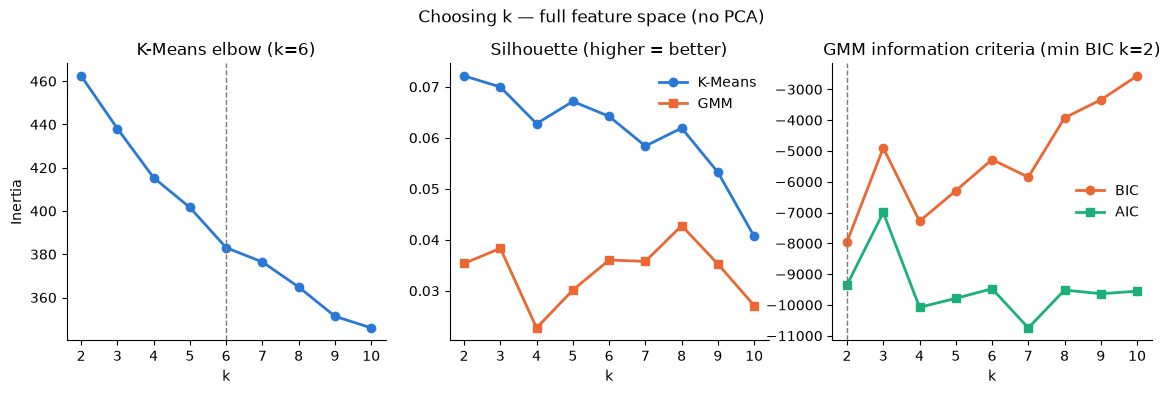

In [53]:
def plot_k_selection(res, choice, title):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    ks = res.index
    axes[0].plot(ks, res["inertia"], "-o", color="#2a78d6", lw=2, ms=6)
    axes[0].axvline(choice["kmeans_elbow"], color="#7a7a7a", ls="--", lw=1)
    axes[0].set(title=f"K-Means elbow (k={choice['kmeans_elbow']})", xlabel="k", ylabel="Inertia")
    axes[1].plot(ks, res["km_silhouette"], "-o", color="#2a78d6", lw=2, ms=6, label="K-Means")
    axes[1].plot(ks, res["gmm_silhouette"], "-s", color="#eb6834", lw=2, ms=6, label="GMM")
    axes[1].set(title="Silhouette (higher = better)", xlabel="k"); axes[1].legend(frameon=False)
    axes[2].plot(ks, res["gmm_bic"], "-o", color="#eb6834", lw=2, ms=6, label="BIC")
    axes[2].plot(ks, res["gmm_aic"], "-s", color="#1baf7a", lw=2, ms=6, label="AIC")
    axes[2].axvline(choice["gmm_min_bic"], color="#7a7a7a", ls="--", lw=1)
    axes[2].set(title=f"GMM information criteria (min BIC k={choice['gmm_min_bic']})", xlabel="k")
    axes[2].legend(frameon=False)
    for a in axes:
        a.spines[["top", "right"]].set_visible(False); a.set_xticks(list(ks))
    fig.suptitle(title, y=1.03, fontsize=12)
    return fig

spaces = {"pca": (X_pca, "diag"), "no_pca": (Xw.values, "diag")}
k_results = {}
for name, (X, cov) in spaces.items():
    res, choice = evaluate_k(X, gmm_cov=cov)
    k_results[name] = (res, choice)
    print(name, choice)
    fig = plot_k_selection(res, choice, f"Choosing k — {'PCA space' if name == 'pca' else 'full feature space (no PCA)'}")
    savefig(fig, f"k_selection_{name}"); plt.show()

In [54]:
def fit_models(X, k_km, k_gmm, cov):
    km = KMeans(n_clusters=k_km, n_init=50, random_state=1).fit(X)
    gm = GaussianMixture(n_components=k_gmm, covariance_type=cov, n_init=10, reg_covar=1e-3,
                         random_state=1).fit(X)
    return km.labels_, gm.predict(X), gm.predict_proba(X).max(axis=1)

K_OVERRIDE = {}
labels = pd.DataFrame(index=Xw.index)
for name, (X, cov) in spaces.items():
    _, choice = k_results[name]
    k_km = K_OVERRIDE.get((name, "kmeans"), choice["kmeans_elbow"])
    k_gm = choice["gmm_min_bic"]
    if k_gm == min(K_RANGE):
        k_gm = int(k_results[name][0]["gmm_silhouette"].idxmax())
        print(f"{name}: min BIC is at the smallest k tested -> using best GMM silhouette k={k_gm} instead")
    k_gm = K_OVERRIDE.get((name, "gmm"), k_gm)
    km_l, gm_l, gm_conf = fit_models(X, k_km, k_gm, cov)
    labels[f"{name}_kmeans"] = km_l
    labels[f"{name}_gmm"] = gm_l
    labels[f"{name}_gmm_conf"] = gm_conf
    print(f"{name}: K-Means k={k_km}, GMM k={k_gm}")

pca: min BIC is at the smallest k tested -> using best GMM silhouette k=2 instead
pca: K-Means k=5, GMM k=2
no_pca: min BIC is at the smallest k tested -> using best GMM silhouette k=8 instead
no_pca: K-Means k=6, GMM k=8


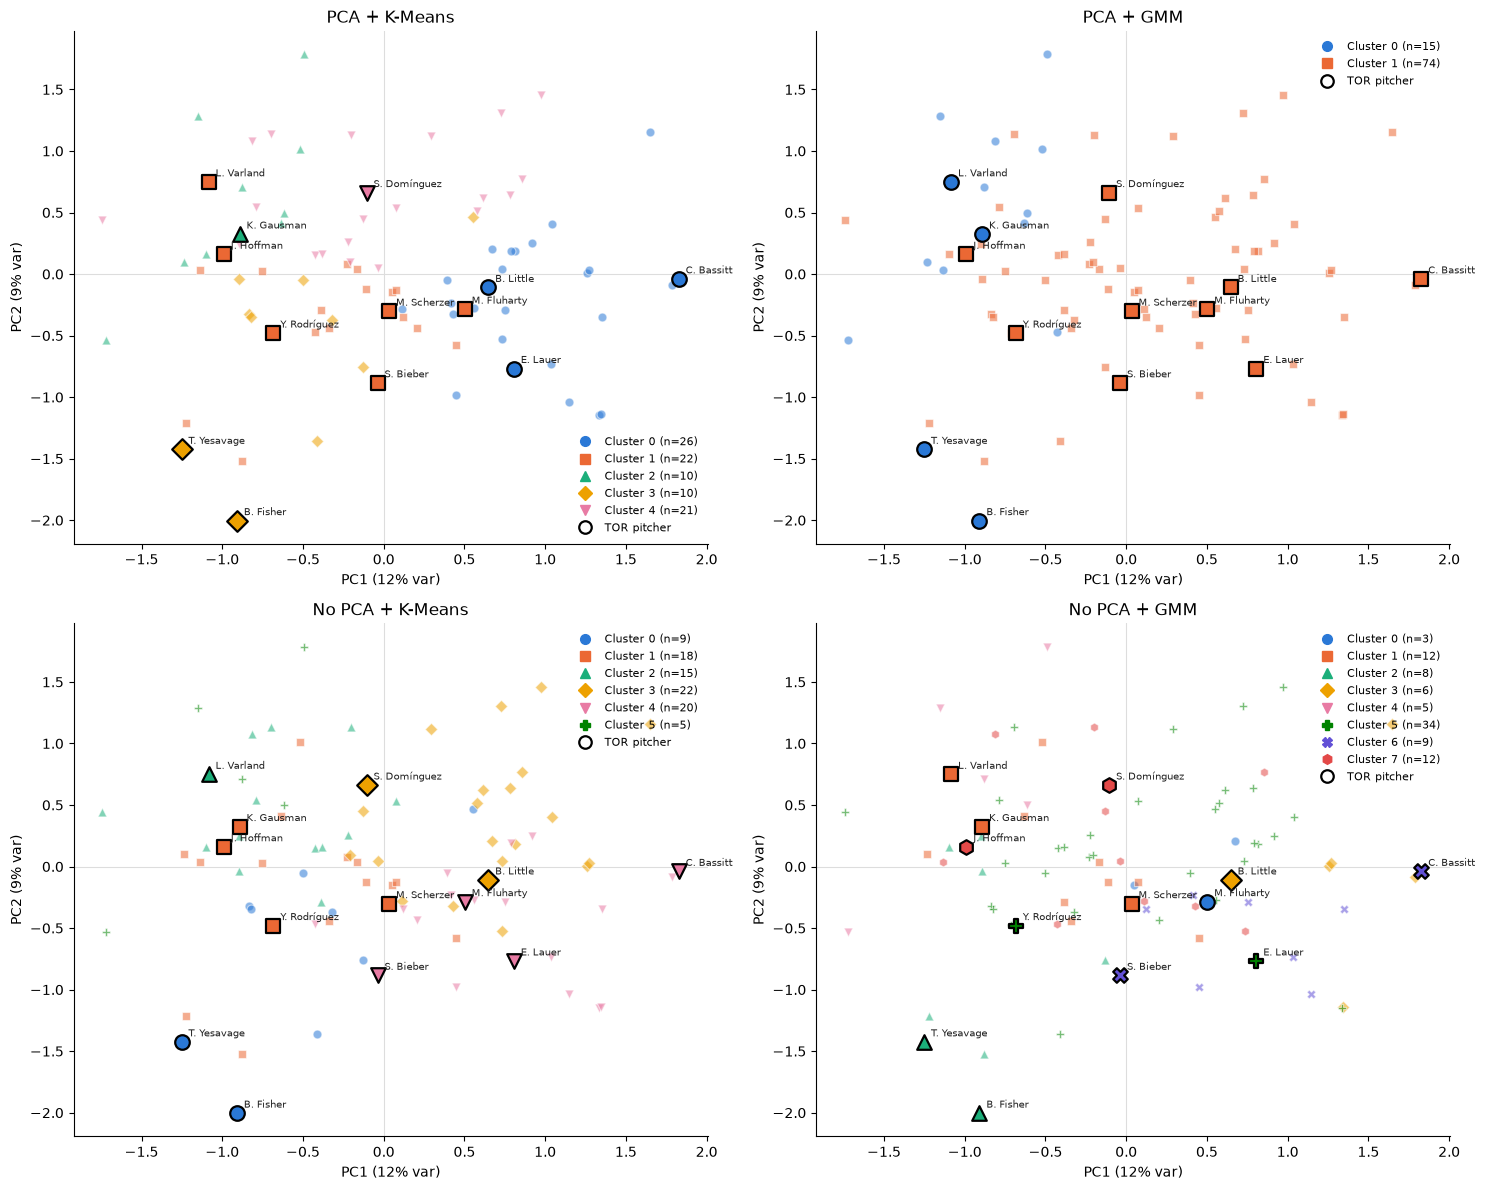

In [55]:
emb2 = PCA(n_components=2, random_state=1).fit(Xw)
E = emb2.transform(Xw)
ev = emb2.explained_variance_ratio_
is_jay = meta.loc[Xw.index, "team"].eq(JAYS).values

def short_name(n):
    parts = [p.strip() for p in str(n).split(",")]
    return f"{parts[1][0]}. {parts[0]}" if len(parts) == 2 and parts[1] else str(n)

def plot_clusters(ax, E, lab, title):
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(E[m & ~is_jay, 0], E[m & ~is_jay, 1], s=40, c=CLUSTER_COLORS[c % 10],
                   marker=CLUSTER_MARKERS[c % 10], alpha=0.55, edgecolors="white", linewidths=0.8)
        ax.scatter(E[m & is_jay, 0], E[m & is_jay, 1], s=110, c=CLUSTER_COLORS[c % 10],
                   marker=CLUSTER_MARKERS[c % 10], edgecolors="black", linewidths=1.6, zorder=3)
    for i in np.where(is_jay)[0]:
        ax.annotate(short_name(meta.loc[Xw.index[i], "player_name"]), E[i], xytext=(5, 4),
                    textcoords="offset points", fontsize=7.5, color="#222222", zorder=4)
    handles = [Line2D([], [], ls="", marker=CLUSTER_MARKERS[c % 10], color=CLUSTER_COLORS[c % 10], ms=7,
                      label=f"Cluster {c} (n={np.sum(lab == c)})") for c in np.unique(lab)]
    handles.append(Line2D([], [], ls="", marker="o", mfc="none", mec="black", mew=1.6, ms=9, label=f"{JAYS} pitcher"))
    ax.legend(handles=handles, frameon=False, fontsize=8, loc="best")
    ax.set(title=title, xlabel=f"PC1 ({ev[0]:.0%} var)", ylabel=f"PC2 ({ev[1]:.0%} var)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.axhline(0, color="#dddddd", lw=0.8, zorder=0); ax.axvline(0, color="#dddddd", lw=0.8, zorder=0)

LABEL_COLS = ["pca_kmeans", "pca_gmm", "no_pca_kmeans", "no_pca_gmm"]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, col in zip(axes.ravel(), LABEL_COLS):
    space, model = col.rsplit("_", 1)
    plot_clusters(ax, E, labels[col].values, f"{'PCA' if space == 'pca' else 'No PCA'} + {'K-Means' if model == 'kmeans' else 'GMM'}")
fig.tight_layout(); savefig(fig, "clusters_2x2"); plt.show()

# Jays Analysis

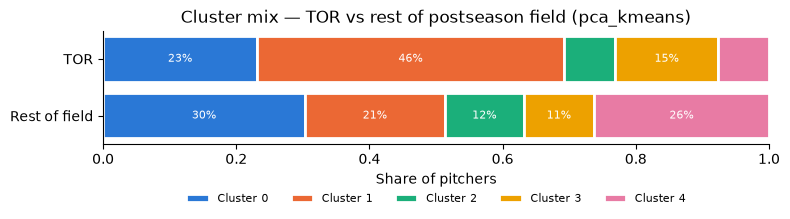

In [56]:
nn = NearestNeighbors(n_neighbors=4).fit(X_pca)
_, idx = nn.kneighbors(X_pca)
names = meta.loc[Xw.index, "player_name"].values
teams = meta.loc[Xw.index, "team"].values

def comps(i, n=3):
    out = [f"{short_name(names[j])} ({teams[j]})" for j in idx[i][1:] if not is_jay[j]]
    if len(out) < n:   # neighbours were Jays; widen the search
        _, wide = NearestNeighbors(n_neighbors=12).fit(X_pca).kneighbors(X_pca[[i]])
        out = [f"{short_name(names[j])} ({teams[j]})" for j in wide[0][1:] if not is_jay[j]]
    return ", ".join(out[:n])

jays_table = meta.loc[Xw.index[is_jay], ["player_name", "p_throws", "n_pitches"]].join(labels.loc[is_jay, LABEL_COLS + ["pca_gmm_conf"]])
jays_table["most_similar"] = [comps(i) for i in np.where(is_jay)[0]]
jays_table.sort_values("n_pitches", ascending=False)

col = "pca_kmeans"
share = pd.crosstab(np.where(is_jay, JAYS, "Rest of field"), labels[col], normalize="index")
fig, ax = plt.subplots(figsize=(8, 2.6))
left = np.zeros(len(share))
for c in share.columns:
    ax.barh(share.index, share[c], left=left, color=CLUSTER_COLORS[c % 10], edgecolor="white", linewidth=2,
            label=f"Cluster {c}")
    for y, (l, v) in enumerate(zip(left, share[c])):
        if v >= 0.08:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white")
    left += share[c].values
ax.set(xlim=(0, 1), xlabel="Share of pitchers", title=f"Cluster mix — {JAYS} vs rest of postseason field ({col})")
ax.legend(frameon=False, ncol=min(len(share.columns), 6), bbox_to_anchor=(0.5, -0.35), loc="upper center", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); savefig(fig, f"team_cluster_mix_{col}"); plt.show()

# Export

In [60]:
PROFILE_COLS = ["usage_grp_FB", "usage_grp_BR", "usage_grp_OS", "n_pitch_types_5pct", "pitch_mix_entropy",
                "FB_velo_mean", "velo_gap_FB_OS", "FB_ivb_mean", "FB_hb_mean", "FB_vaa_mean", "BR_hb_mean",
                "BR_spin_mean", "ext_mean", "rel_z_mean", "arm_angle_proxy",
                "zone_pct", "whiff_pct", "chase_pct", "csw_pct",
                "nonfb_pct_two_strikes", "fb_shift_behind_vs_ahead", "platoon_os_shift",
                "k_pct", "bb_pct", "gb_pct", "ip_per_app_mean", "start_pct", "throws_left"]

def cluster_profile(label_col):
    cols = [c for c in PROFILE_COLS if c in X_imputed]
    prof = X_imputed[cols].groupby(labels[label_col]).mean()
    prof.insert(0, "n", labels[label_col].value_counts().sort_index())
    jays = meta.loc[labels.index[is_jay], "player_name"].groupby(labels.loc[is_jay, label_col]).apply(
        lambda s: ", ".join(short_name(n) for n in s))
    prof[f"{JAYS}_pitchers"] = jays.reindex(prof.index).fillna("")
    return prof

def plot_profile_heatmap(label_col):
    cols = [c for c in PROFILE_COLS if c in X_imputed]
    z = (X_imputed[cols] - X_imputed[cols].mean()) / X_imputed[cols].std()
    zc = z.groupby(labels[label_col]).mean().T
    fig, ax = plt.subplots(figsize=(1.1 * zc.shape[1] + 3, 0.32 * len(cols) + 1.5))
    im = ax.imshow(zc.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")   # diverging, neutral midpoint
    ax.set_xticks(range(zc.shape[1]), [f"C{c}" for c in zc.columns])
    ax.set_yticks(range(len(cols)), cols, fontsize=8)
    for i in range(zc.shape[0]):
        for j in range(zc.shape[1]):
            ax.text(j, i, f"{zc.values[i, j]:+.1f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(zc.values[i, j]) > 1 else "#222222")
    fig.colorbar(im, ax=ax, label="cluster mean (z-score vs all pitchers)", shrink=0.6)
    ax.set_title(f"Cluster profiles — {label_col}")
    fig.tight_layout(); savefig(fig, f"profile_{label_col}"); plt.show()

cluster_profile("pca_kmeans").round(2)

,n,usage_grp_FB,usage_grp_BR,usage_grp_OS,n_pitch_types_5pct,pitch_mix_entropy,FB_velo_mean,velo_gap_FB_OS,FB_ivb_mean,FB_hb_mean,BR_hb_mean,BR_spin_mean,ext_mean,rel_z_mean,arm_angle_proxy,zone_pct,whiff_pct,chase_pct,csw_pct,fb_shift_behind_vs_ahead,k_pct,bb_pct,gb_pct,ip_per_app_mean,start_pct,TOR_pitchers
pca_kmeans,,,,,,,,,,,,,,,,,,,,,,,,,,
0,26,0.67,0.26,0.07,4.54,2.02,93.53,7.63,11.00,7.64,-10.58,2585.02,6.28,5.91,72.49,0.51,0.23,0.28,0.28,0.14,0.21,0.08,0.42,2.93,0.34,"C. Bassitt, E. Lauer, B. Little"
1,22,0.41,0.46,0.12,3.95,1.82,94.90,7.65,13.95,8.17,-7.76,2544.79,6.59,5.60,66.67,0.48,0.29,0.30,0.30,0.06,0.25,0.09,0.41,2.88,0.46,"M. Scherzer, J. Hoffman, S. Bieber, Y. Rodrígu..."
2,10,0.47,0.10,0.43,2.70,1.27,95.52,10.28,15.13,9.73,-5.30,2340.29,7.00,5.74,70.53,0.46,0.28,0.30,0.27,0.11,0.21,0.10,0.41,2.38,0.36,K. Gausman
3,10,0.51,0.43,0.06,3.20,1.45,94.77,8.68,18.36,5.37,-2.83,2457.05,6.22,6.20,82.52,0.54,0.29,0.34,0.32,0.04,0.27,0.08,0.33,1.78,0.32,"B. Fisher, T. Yesavage"
4,21,0.64,0.28,0.08,3.24,1.55,97.58,8.30,13.00,11.18,-7.15,2495.99,6.40,5.60,72.07,0.54,0.24,0.30,0.28,0.10,0.24,0.09,0.45,2.22,0.26,S. Domínguez


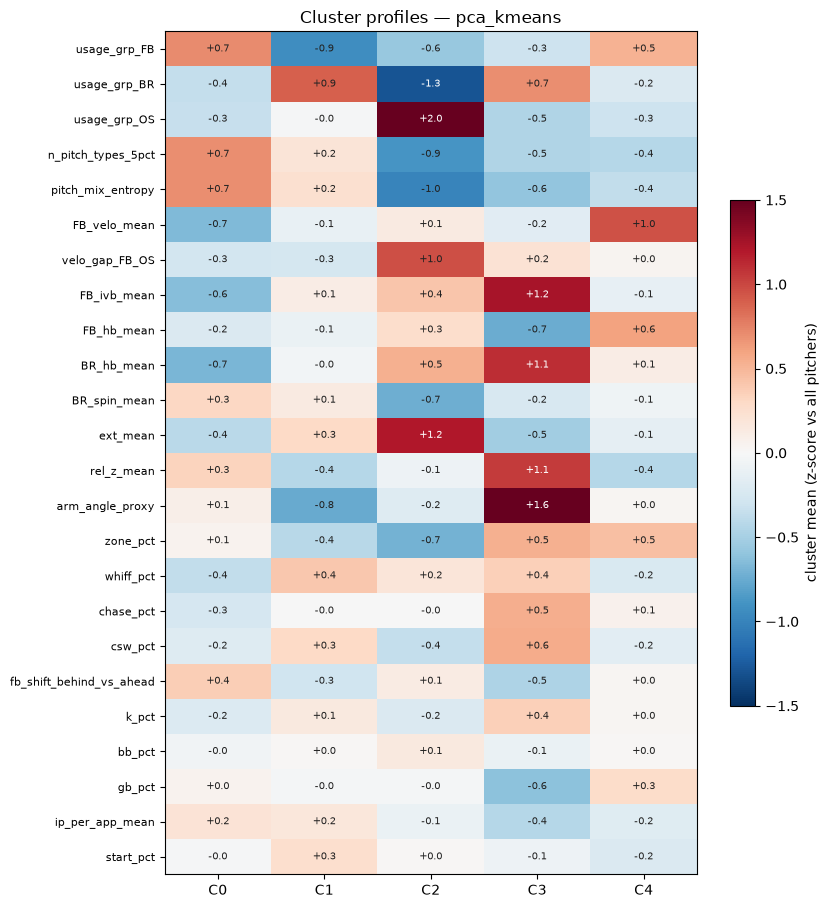

In [61]:
plot_profile_heatmap("pca_kmeans")

In [62]:
nn = NearestNeighbors(n_neighbors=4).fit(X_pca)
_, idx = nn.kneighbors(X_pca)
names = meta.loc[Xw.index, "player_name"].values
teams = meta.loc[Xw.index, "team"].values

def comps(i, n=3):
    out = [f"{short_name(names[j])} ({teams[j]})" for j in idx[i][1:] if not is_jay[j]]
    if len(out) < n:   # neighbours were Jays; widen the search
        _, wide = NearestNeighbors(n_neighbors=12).fit(X_pca).kneighbors(X_pca[[i]])
        out = [f"{short_name(names[j])} ({teams[j]})" for j in wide[0][1:] if not is_jay[j]]
    return ", ".join(out[:n])

jays_table = meta.loc[Xw.index[is_jay], ["player_name", "p_throws", "n_pitches"]].join(labels.loc[is_jay, LABEL_COLS + ["pca_gmm_conf"]])
jays_table["most_similar"] = [comps(i) for i in np.where(is_jay)[0]]
jays_table.sort_values("n_pitches", ascending=False)

,player_name,p_throws,n_pitches,pca_kmeans,pca_gmm,no_pca_kmeans,no_pca_gmm,pca_gmm_conf,most_similar
pitcher,,,,,,,,,
702056,"Yesavage, Trey",R,440,3,0,0,2,0.972067,"B. Snell (LAD), C. Rodón (NYY), T. Skubal (DET)"
592332,"Gausman, Kevin",R,436,2,0,1,1,0.852010,"K. Finnegan (DET), C. Mize (DET), C. Rodón (NYY)"
669456,"Bieber, Shane",R,310,1,1,4,6,0.999659,"C. Rea (CHC), J. Flaherty (DET), R. Gasser (MIL)"
686973,"Varland, Louis",R,250,1,0,2,1,0.854171,"J. Flaherty (DET), J. Duran (PHI), G. Kirby (SEA)"
453286,"Scherzer, Max",R,220,1,1,1,1,0.999301,"J. Flaherty (DET), K. Montero (DET), F. Peralt..."
656546,"Hoffman, Jeff",R,207,1,1,1,7,0.701524,"W. Vest (DET), A. Banda (LAD), J. Flaherty (DET)"
622554,"Domínguez, Seranthony",R,199,4,1,3,7,0.998398,"B. Miller (SEA), W. Vest (DET), B. Woo (SEA)"
689254,"Fluharty, Mason",L,138,1,1,4,0,0.999910,"R. Gasser (MIL), W. Warren (NYY), S. Imanaga (..."
641778,"Lauer, Eric",L,136,0,1,4,5,1.000000,"R. Suárez (PHI), K. Montero (DET), A. Civale (..."


In [57]:
out = meta.join(labels).join(features)
out.to_csv("pitcher_clusters.csv")
print("saved pitcher_clusters.csv", out.shape)

saved pitcher_clusters.csv (89, 150)
